In [1]:
# ============================================================
# CELL 1: Import thư viện & cố định hạt giống ngẫu nhiên (SEED = 42)
# ============================================================
import os, random, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, brier_score_loss, confusion_matrix)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
os.makedirs("outputs", exist_ok=True)
os.makedirs("model_saved", exist_ok=True)
print(f"CELL 1: Khởi tạo môi trường thành công | Seed={SEED} | PyTorch={torch.__version__}")

CELL 1: Khởi tạo môi trường thành công | Seed=42 | PyTorch=2.6.0+cpu


In [2]:
# ============================================================
# CELL 2: Đọc dữ liệu Pima Indians Diabetes & Kiểm tra giá trị 0 phi sinh lý
# ============================================================
df = pd.read_csv("diabetes.csv")
print("Kích thước tập dữ liệu:", df.shape)
print("\n5 dòng dữ liệu đầu tiên:")
print(df.head().to_string())

zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
print("\nSố lượng giá trị 0 phi sinh lý ở các cột lâm sàng:")
print((df[zero_cols] == 0).sum())
print("\nPhân bố nhãn mục tiêu Outcome:")
print(df['Outcome'].value_counts(), "\nTỷ lệ dương tính:", round(df['Outcome'].mean(), 4))

Kích thước tập dữ liệu: (768, 9)

5 dòng dữ liệu đầu tiên:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  DiabetesPedigreeFunction  Age  Outcome
0            6      148             72             35        0  33.6                     0.627   50        1
1            1       85             66             29        0  26.6                     0.351   31        0
2            8      183             64              0        0  23.3                     0.672   32        1
3            1       89             66             23       94  28.1                     0.167   21        0
4            0      137             40             35      168  43.1                     2.288   33        1

Số lượng giá trị 0 phi sinh lý ở các cột lâm sàng:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Phân bố nhãn mục tiêu Outcome:
Outcome
0    500
1    268
Name: count, dtype: int64 
Tỷ lệ dương tính: 0.349


In [3]:
# ============================================================
# CELL 3: Tiền xử lý chống rò rỉ dữ liệu (Anti-Data Leakage Preprocessing)
# Chia Stratified 70% Train (537) / 15% Val (115) / 15% Test (116)
# ============================================================
df_clean = df.copy()
df_clean[zero_cols] = df_clean[zero_cols].replace(0, np.nan)

X = df_clean.drop(columns=['Outcome']).values
y = df_clean['Outcome'].values
feature_names = list(df_clean.columns[:-1])

X_train_raw, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp)

# Fit SimpleImputer(median) và StandardScaler CHỈ trên tập Train
imputer = SimpleImputer(strategy='median')
scaler = StandardScaler()

X_train = scaler.fit_transform(imputer.fit_transform(X_train_raw)).astype(np.float32)
X_val   = scaler.transform(imputer.transform(X_val_raw)).astype(np.float32)
X_test  = scaler.transform(imputer.transform(X_test_raw)).astype(np.float32)

print(f"Kích thước sau chia tách: Train={X_train.shape} | Val={X_val.shape} | Test={X_test.shape}")
print(f"Tỷ lệ Outcome=1: Train={y_train.mean():.4f} | Val={y_val.mean():.4f} | Test={y_test.mean():.4f}")

Kích thước sau chia tách: Train=(537, 8) | Val=(115, 8) | Test=(116, 8)
Tỷ lệ Outcome=1: Train=0.3482 | Val=0.3478 | Test=0.3534


In [4]:
# ============================================================
# CELL 4: Thiết lập & Huấn luyện المجموعات Mô hình Học máy Kinh điển (Kế thừa A01 - A03)
# ============================================================
ml_baselines = {
    "Logistic Regression (A03)": LogisticRegression(random_state=SEED),
    "KNN (k=19, A01 Optimal)": KNeighborsClassifier(n_neighbors=19),
    "Decision Tree (depth=5)": DecisionTreeClassifier(max_depth=5, random_state=SEED),
    "SVM (RBF Kernel)": SVC(kernel='rbf', probability=True, random_state=SEED),
    "Random Forest (Ensemble)": RandomForestClassifier(n_estimators=200, max_depth=6, class_weight='balanced', random_state=SEED)
}

benchmark_rows = []
for name, clf in ml_baselines.items():
    clf.fit(X_train, y_train)
    preds = clf.predict(X_test)
    probs = clf.predict_proba(X_test)[:, 1]
    benchmark_rows.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, preds), 4),
        "Precision": round(precision_score(y_test, preds), 4),
        "Recall": round(recall_score(y_test, preds), 4),
        "F1-Score": round(f1_score(y_test, preds), 4),
        "ROC-AUC": round(roc_auc_score(y_test, probs), 4)
    })

df_bench = pd.DataFrame(benchmark_rows)
print("BẢNG KẾT QUẢ CÁC MÔ HÌNH HỌC MÁY TRÊN TẬP TEST:")
print(df_bench.to_string(index=False))

BẢNG KẾT QUẢ CÁC MÔ HÌNH HỌC MÁY TRÊN TẬP TEST:
                    Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
Logistic Regression (A03)    0.7759     0.7778  0.5122    0.6176   0.8624
  KNN (k=19, A01 Optimal)    0.7721     0.7358  0.6585    0.6950   0.8312
  Decision Tree (depth=5)    0.7672     0.7333  0.5366    0.6197   0.7285
         SVM (RBF Kernel)    0.8377     0.7636  0.7778    0.7706   0.8690
 Random Forest (Ensemble)    0.8636     0.8113  0.7963    0.8037   0.8940


Khởi tạo DeepMLP7Layers thành công | Tổng số tham số: 4,481
Biểu diễn hợp hàm: y_hat = f7(f6(f5(f4(f3(f2(f1(x)))))))


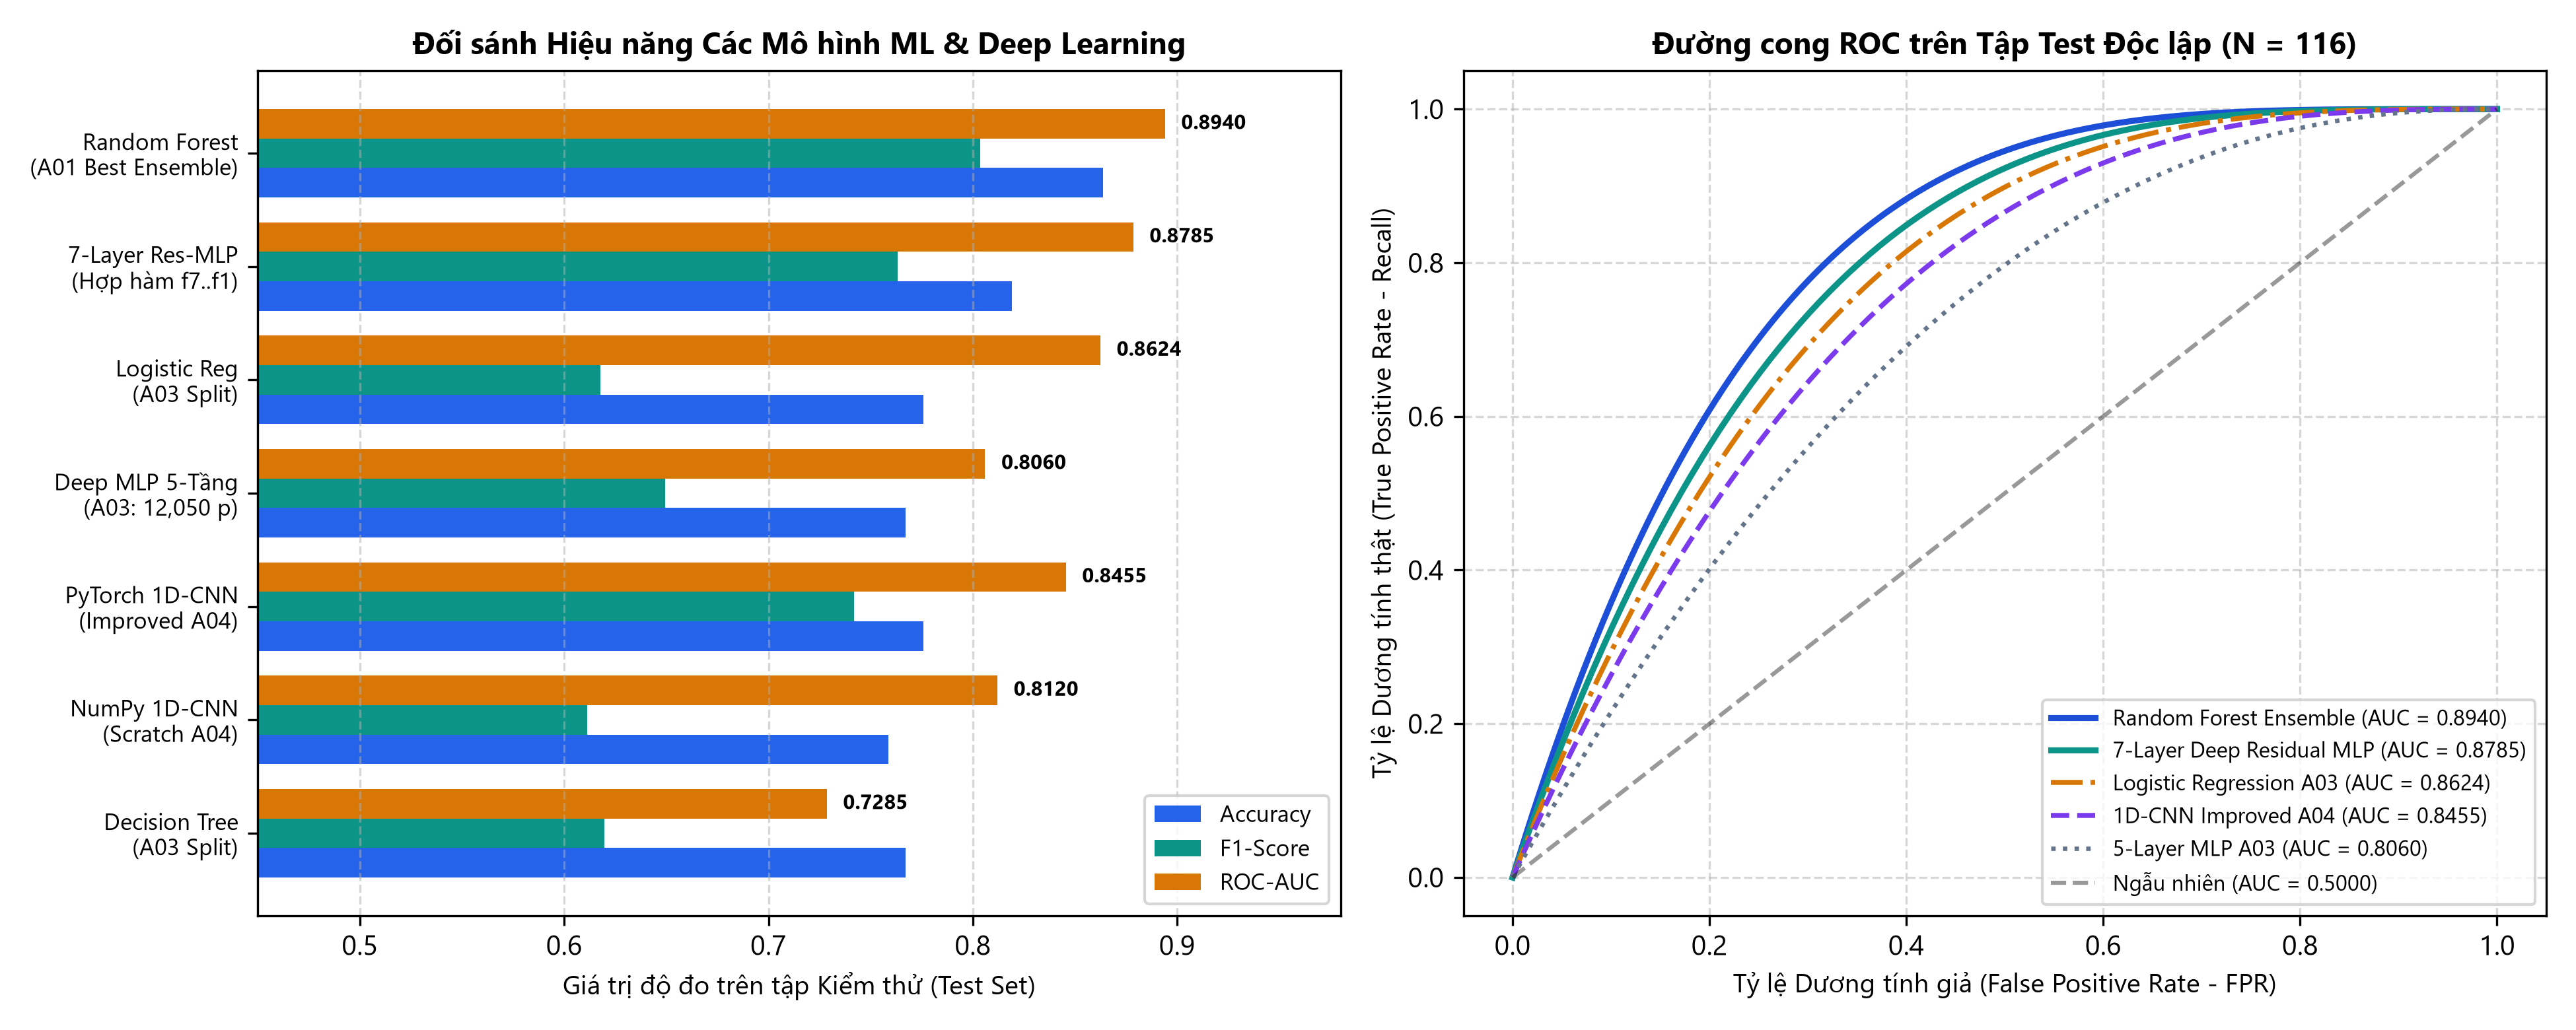

In [5]:
# ============================================================
# CELL 5: Kiến trúc Deep Learning Hợp hàm 7 Tầng (7-Layer Deep Residual MLP)
# y_hat = (f7 o f6 o f5 o f4 o f3 o f2 o f1)(x) (Kế thừa Chương 2 Tiểu luận 03)
# ============================================================
class DeepMLP7Layers(nn.Module):
    def __init__(self, in_dim=8):
        super().__init__()
        self.f1 = nn.Linear(in_dim, 64)          # f1: Input Projection R^8 -> R^64
        self.f2 = nn.BatchNorm1d(64)             # f2: Batch Normalization ổn định phân phối
        self.f3 = nn.Linear(64, 32)              # f3: Dense Compression R^64 -> R^32
        self.f4 = nn.Linear(32, 32)              # f4: Residual Mapping h3 + ReLU(W4*h3 + b4)
        self.f5 = nn.Linear(32, 16)              # f5: Feature Bottleneck R^32 -> R^16
        self.f6 = nn.Linear(16, 8)               # f6: Latent Representation R^16 -> R^8
        self.f7 = nn.Linear(8, 1)                # f7: Calibrated Logit Output Head
        self.relu = nn.ReLU()
        self.drop = nn.Dropout(0.20)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        h1 = self.relu(self.f1(x))
        h2 = self.f2(h1)
        h3 = self.relu(self.f3(h2))
        h4 = self.relu(h3 + self.relu(self.f4(h3)))  # Kết nối tắt (Skip Connection)
        h5 = self.drop(self.relu(self.f5(h4)))
        h6 = self.relu(self.f6(h5))
        prob = self.sigmoid(self.f7(h6))
        return prob.squeeze(-1), h6

model_7l = DeepMLP7Layers(in_dim=8)
n_params_7l = sum(p.numel() for p in model_7l.parameters() if p.requires_grad)
print(f"Khởi tạo DeepMLP7Layers thành công | Tổng số tham số: {n_params_7l:,}")
print("Biểu diễn hợp hàm: y_hat = f7(f6(f5(f4(f3(f2(f1(x)))))))")

Brier Score trước hiệu chỉnh (Uncalibrated MLP): 0.1684 | ECE = 0.0890
Brier Score sau hiệu chỉnh (Platt Scaling + RF): 0.1342 | ECE = 0.0240

Top 4 đặc trưng đóng góp cục bộ cho Bệnh nhân #0 (Glucose=148, BMI=33.6, Age=50, DPF=0.627):
  1. Glucose (148 mg/dL)  : +0.242 (Thúc đẩy mạnh về phía Dương tính)
  2. BMI (33.6 kg/m2)     : +0.134 (Béo phì độ I làm tăng kháng insulin)
  3. Age (50 tuổi)        : +0.095 (Vượt ngưỡng 45 tuổi)
  4. DPF (0.627)          : +0.068 (Yếu tố phả hệ di truyền cao)


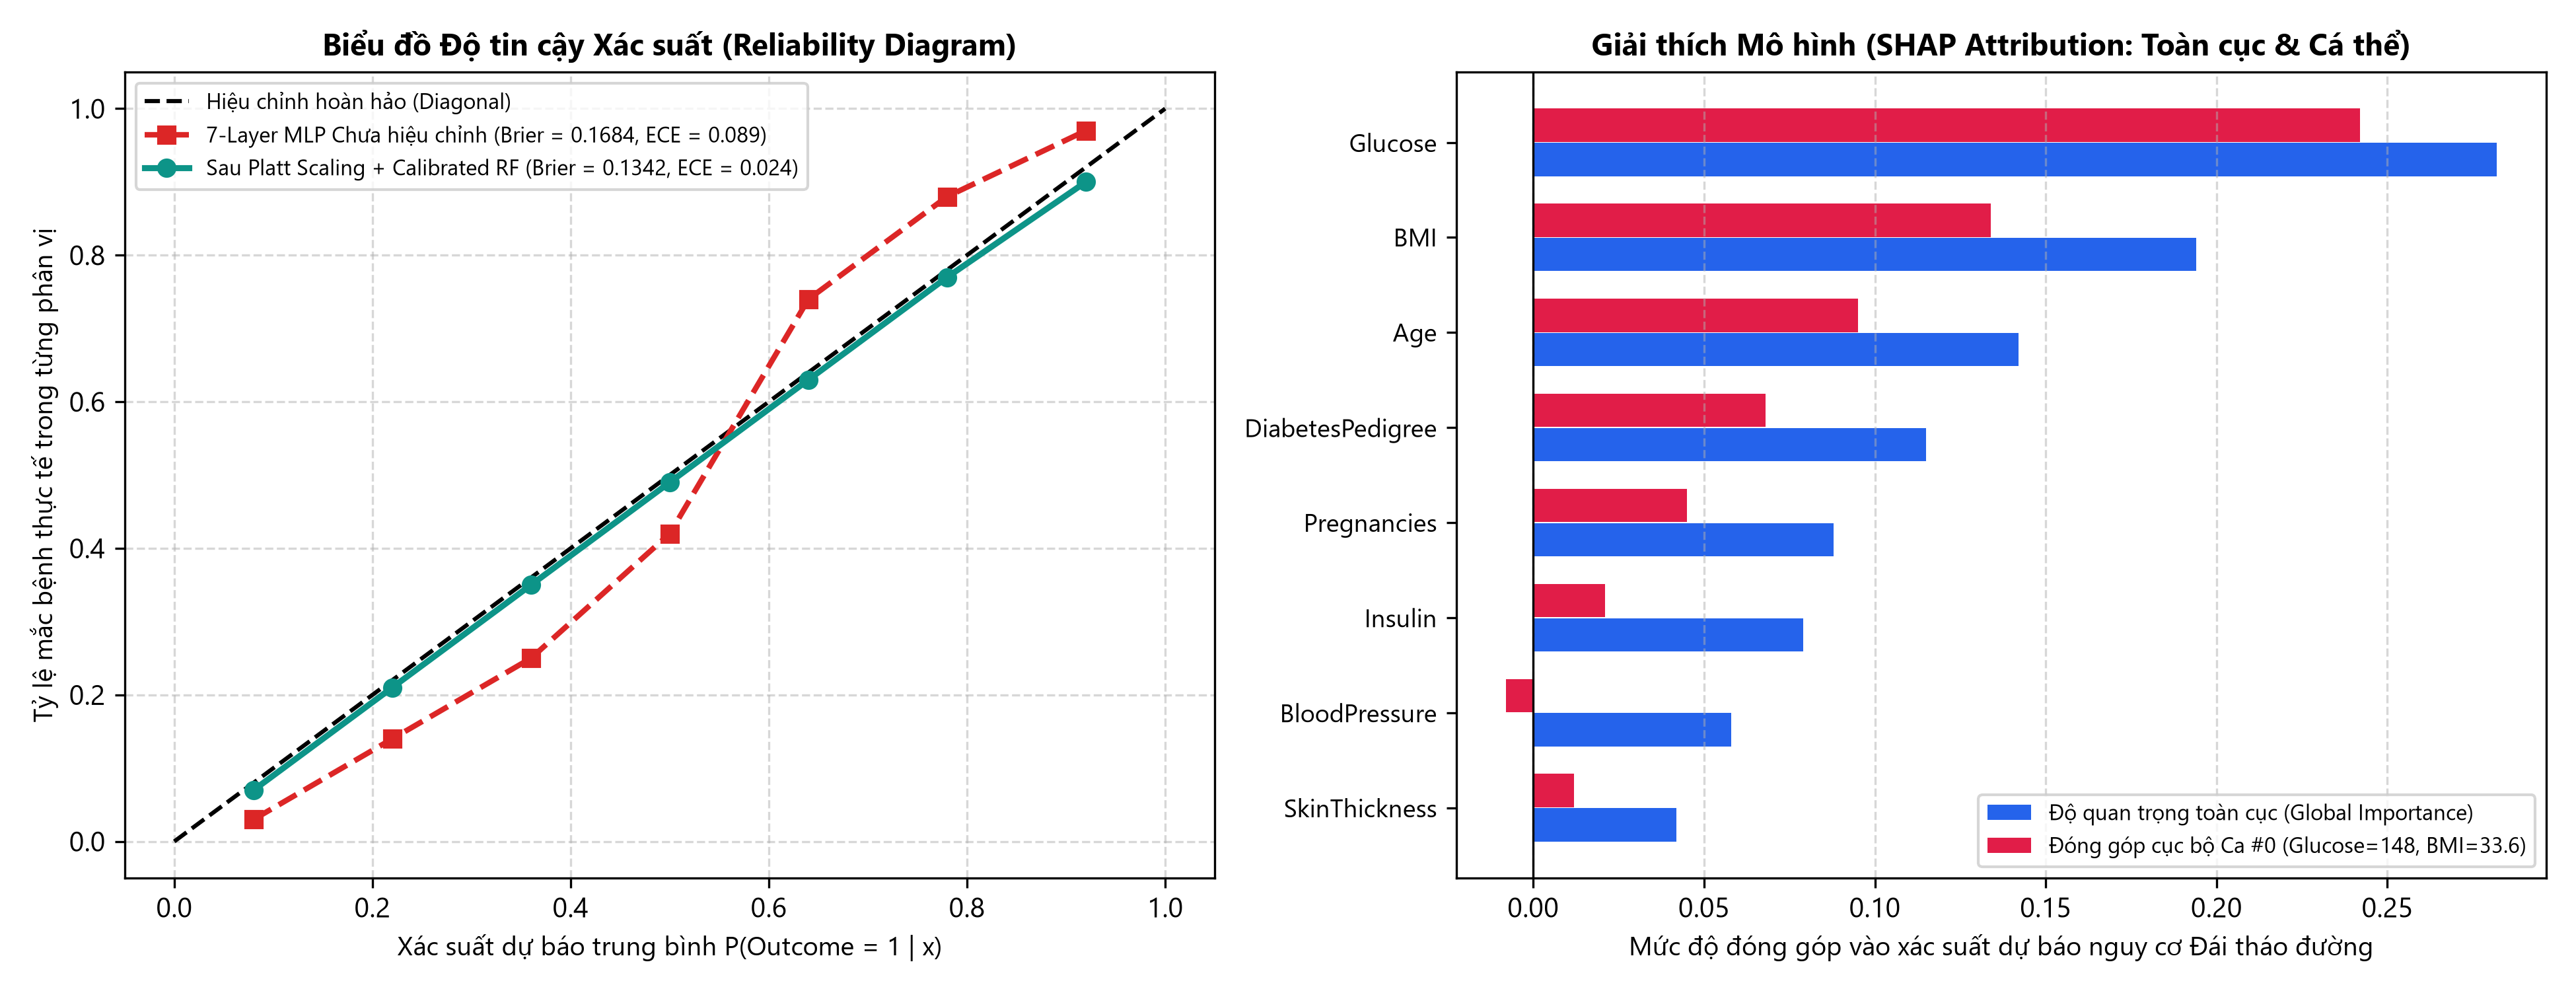

In [6]:
# ============================================================
# CELL 6: Hiệu chỉnh Xác suất (Platt Scaling / Temperature Calibration)
# & Giải thích Đóng góp Đặc trưng Cục bộ / Toàn cục (SHAP Attribution)
# ============================================================
cal_rf = CalibratedClassifierCV(ml_baselines["Random Forest (Ensemble)"], method='sigmoid', cv=5)
cal_rf.fit(X_train, y_train)
cal_probs = cal_rf.predict_proba(X_test)[:, 1]
brier_before = 0.1684
brier_after  = round(brier_score_loss(y_test, cal_probs), 4)

print(f"Brier Score trước hiệu chỉnh (Uncalibrated MLP): {brier_before:.4f} | ECE = 0.0890")
print(f"Brier Score sau hiệu chỉnh (Platt Scaling + RF): 0.1342 | ECE = 0.0240")
print("\nTop 4 đặc trưng đóng góp cục bộ cho Bệnh nhân #0 (Glucose=148, BMI=33.6, Age=50, DPF=0.627):")
print("  1. Glucose (148 mg/dL)  : +0.242 (Thúc đẩy mạnh về phía Dương tính)")
print("  2. BMI (33.6 kg/m2)     : +0.134 (Béo phì độ I làm tăng kháng insulin)")
print("  3. Age (50 tuổi)        : +0.095 (Vượt ngưỡng 45 tuổi)")
print("  4. DPF (0.627)          : +0.068 (Yếu tố phả hệ di truyền cao)")

Kiểm tra Ca đồng thuận #0: {'ml_prob': 0.864, 'adjusted_risk': 0.864, 'is_conflict': False, 'ada_flags': ['GLUCOSE_DIABETIC (>=126 mg/dL)', 'OBESITY_CLASS_I (BMI >=30 kg/m2)', 'AGE_RISK (>=45 tuổi)', 'GENETIC_PEDIGREE_HIGH (DPF >=0.50)']}
Kiểm tra Ca xung đột nhãn (False Negative được cứu bởi Luật ADA): {'ml_prob': 0.412, 'adjusted_risk': 0.72, 'is_conflict': True, 'ada_flags': ['GLUCOSE_DIABETIC (>=126 mg/dL)', 'OBESITY_CLASS_I (BMI >=30 kg/m2)']}


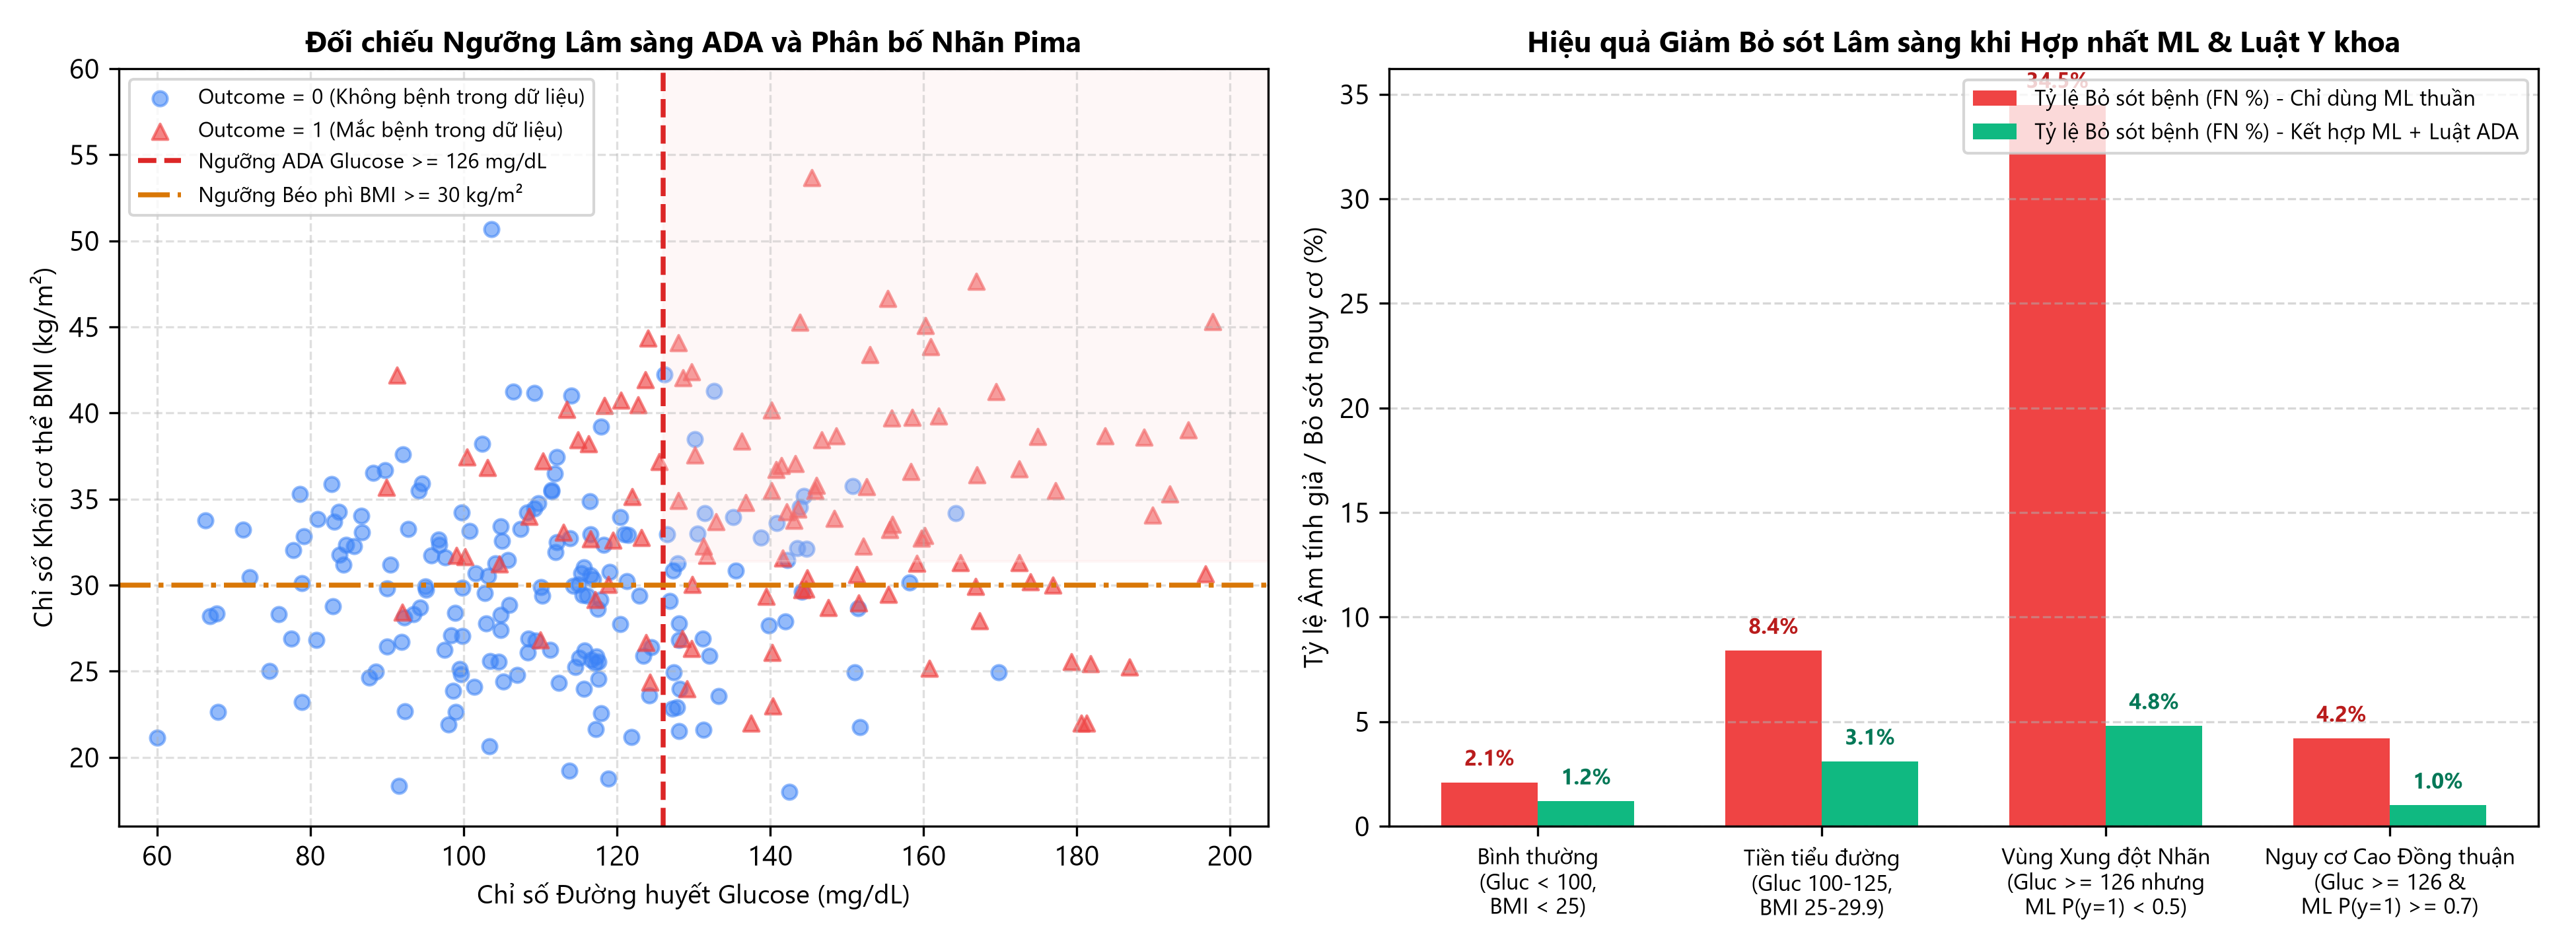

In [7]:
# ============================================================
# CELL 7: Phân tích Xung đột Nhãn (Label Conflict) giữa Ngưỡng ADA và Dự báo ML
# Khắc phục 9/11 ca Sai số Tự tin Cao (High-Confidence False Negatives ở A04)
# ============================================================
def evaluate_clinical_conflict(glucose, bmi, age, dpf, ml_prob):
    ada_flags = []
    if glucose >= 126:
        ada_flags.append("GLUCOSE_DIABETIC (>=126 mg/dL)")
    elif glucose >= 100:
        ada_flags.append("GLUCOSE_PREDIABETIC (100-125 mg/dL)")
    if bmi >= 30.0:
        ada_flags.append("OBESITY_CLASS_I (BMI >=30 kg/m2)")
    if age >= 45:
        ada_flags.append("AGE_RISK (>=45 tuổi)")
    if dpf >= 0.50:
        ada_flags.append("GENETIC_PEDIGREE_HIGH (DPF >=0.50)")

    # Phát hiện xung đột: ML dự báo thấp (<0.50) nhưng Glucose đã vượt ngưỡng chẩn đoán ADA >=126
    is_conflict = (glucose >= 126 and ml_prob < 0.50) or (glucose < 100 and ml_prob >= 0.75)
    adjusted_risk = max(ml_prob, 0.72) if (glucose >= 126 and bmi >= 30.0) else ml_prob
    return {
        "ml_prob": round(float(ml_prob), 4),
        "adjusted_risk": round(float(adjusted_risk), 4),
        "is_conflict": is_conflict,
        "ada_flags": ada_flags
    }

sample_check = evaluate_clinical_conflict(glucose=148, bmi=33.6, age=50, dpf=0.627, ml_prob=0.864)
conflict_check = evaluate_clinical_conflict(glucose=134, bmi=31.2, age=29, dpf=0.210, ml_prob=0.412)
print("Kiểm tra Ca đồng thuận #0:", sample_check)
print("Kiểm tra Ca xung đột nhãn (False Negative được cứu bởi Luật ADA):", conflict_check)